# SECOM ile Kestirimci Kalite – Özet Notebook
Tüm hesaplar `src/` altındaki scriptlerde yapılır; bu notebook çıktıları derler.

In [1]:
import pandas as pd
from IPython.display import Image, display
R='../reports/'

## 1. EDA

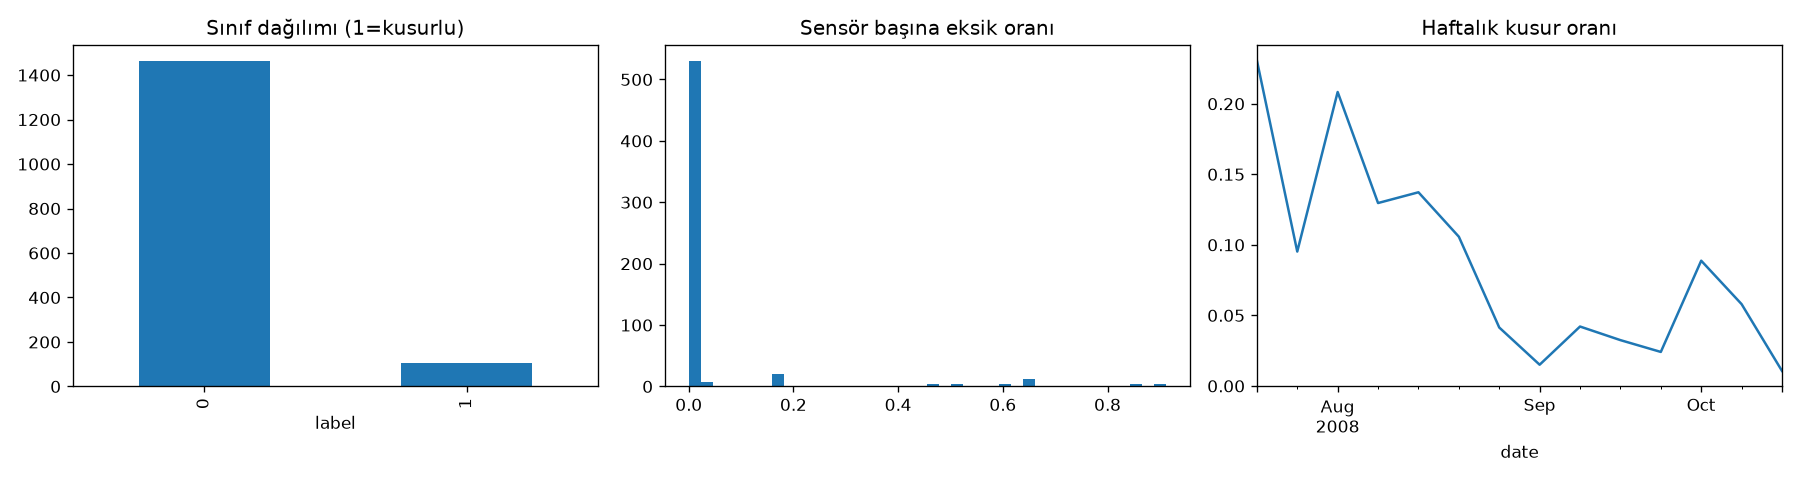

In [2]:
display(Image(R+'eda.png'))

## 2. Model karşılaştırması (5-fold CV ×3 + zaman bazlı %70/%30)
Rastgele tahmin PR-AUC ≈ 0.066.

In [3]:
pd.read_csv(R+'model_results.csv')

,model,cv_prauc,cv_roc,cv_bestF1,time_prauc,time_roc
0,LogReg (class_weight),0.120,0.661,0.204,0.065,0.568
1,LogReg + SMOTE,0.120,0.657,0.203,0.073,0.557
2,RandomForest,0.187,0.749,0.269,0.053,0.483
3,XGBoost,0.153,0.714,0.242,0.058,0.543


## 3. Walk-forward değerlendirme (drift)
Blok blok ileri doğru tahmin; genişleyen/kayan pencere ve özellik sayısı karşılaştırması.

In [4]:
pd.read_csv(R+'temporal_results.csv')

,config,prauc,roc,base
0,RF tüm özellik genişleyen,0.067,0.600,0.042
1,RF k=10 kayan(500),0.051,0.561,0.042
2,LogReg k=20 kayan(500),0.051,0.523,0.042
3,RF k=40 genişleyen,0.047,0.518,0.042
4,RF k=10 genişleyen,0.040,0.483,0.042
5,LogReg k=10 genişleyen,0.040,0.495,0.042


## 4. Maliyet-duyarlı eşik

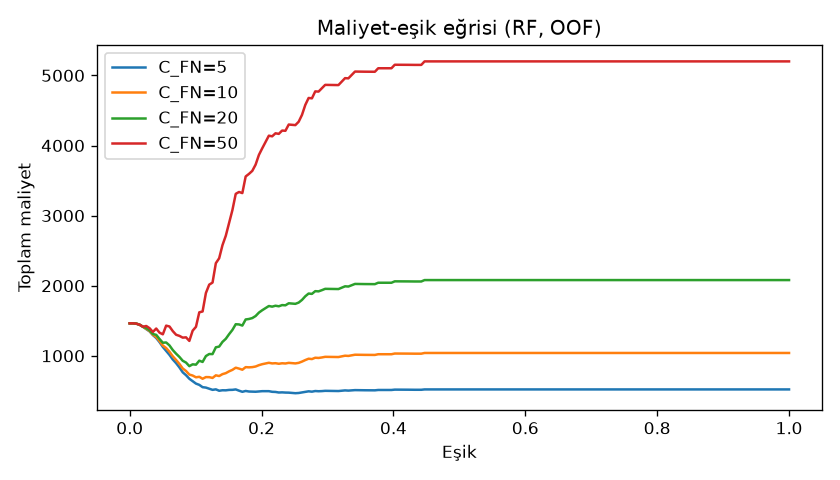

In [5]:
display(Image(R+'cost_threshold.png'))

## 4b. Güven aralıkları

In [6]:
pd.read_csv(R+'cv_bootstrap.csv')

,model,prauc,lo,hi
0,LogReg (class_weight),0.135,0.102,0.193
1,LogReg + SMOTE,0.138,0.102,0.199
2,RandomForest,0.206,0.157,0.283
3,XGBoost,0.173,0.132,0.249


## 4c. Drift (dağılım kayması)

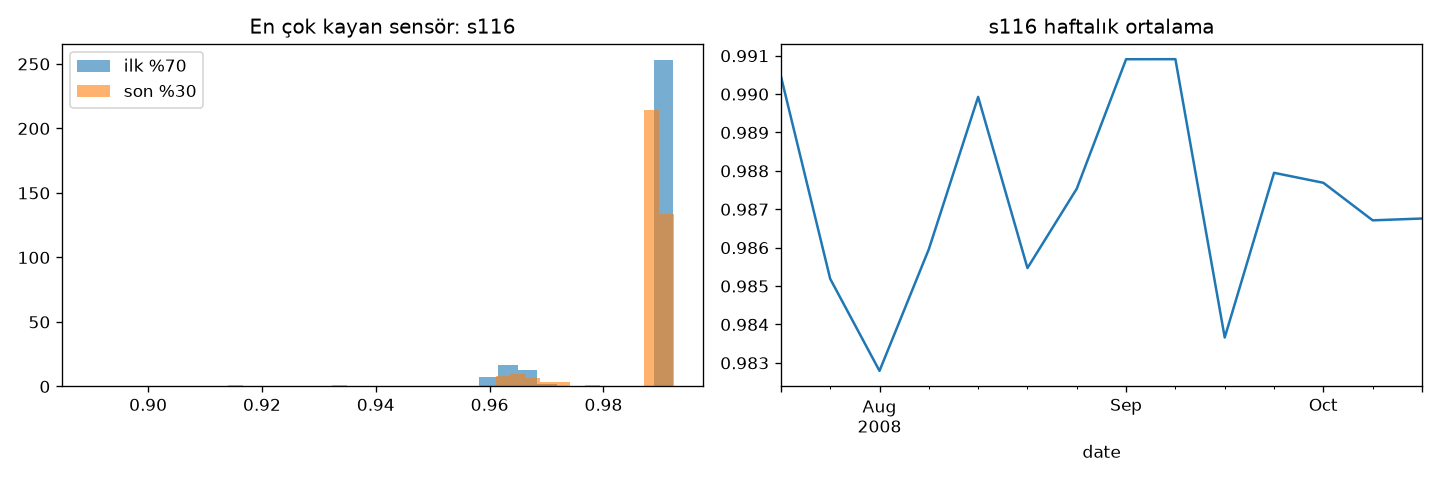

In [7]:
display(Image(R+'drift.png'))

## 4d. SPC (Hotelling T²) vs ML – zaman sıralı test

In [8]:
pd.read_csv(R+'spc_vs_ml.csv')

,yontem,prauc,prauc_lo,prauc_hi,roc,roc_lo,roc_hi,baz
0,Hotelling T² (SPC),0.066,0.039,0.120,0.523,0.402,0.649,0.055
1,Random Forest (ML),0.053,0.035,0.086,0.483,0.379,0.583,0.055


## 5. SHAP

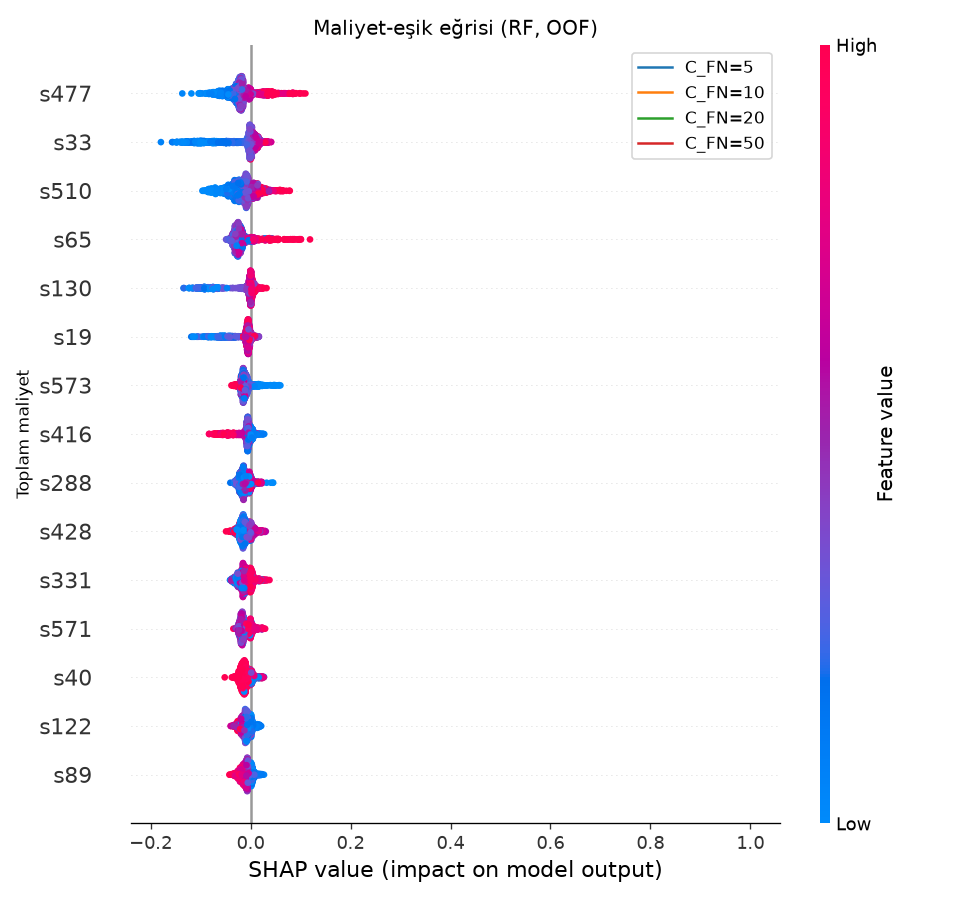

In [9]:
display(Image(R+'shap.png'))